<a href="https://colab.research.google.com/github/AnshG-19/Blackhole_simulator_rayTracing/blob/main/notebooks/05_accretion_disk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Black Hole Simulator — Accretion Disk

## Objectives
- Model an accretion disk around a black hole
- Create a radial brightness profile
- Visualize disk temperature using colour
- Understand the limits of a top-down model


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

print("Accretion disk simulation initialized.")

Accretion disk simulation initialized.


Define the black hole and disk

1.   Why use these values?
- The event horizon is at \(r=2M\).
- The photon sphere is at \(r=3M\).
- The disk begins at \(r=6M\), the innermost stable circular orbit for a Schwarzschild black hole in the idealized test-particle model.
- The disk ends at \(r=20M\) for this visualization.



In [2]:
# Geometric units: G = c = M = 1
M = 1.0

# Black hole geometry
r_s = 2 * M
r_ph = 3 * M

# Simplified accretion disk boundaries
r_inner = 6 * M
r_outer = 20 * M

print("Event horizon radius:", r_s)
print("Photon sphere radius:", r_ph)
print("Disk inner radius:", r_inner)
print("Disk outer radius:", r_outer)

Event horizon radius: 2.0
Photon sphere radius: 3.0
Disk inner radius: 6.0
Disk outer radius: 20.0


Create a 2D grid
What is happening here?
1. np.linspace() generates evenly spaced coordinates.
2. np.meshgrid() combines the horizontal and vertical coordinates into a 2D grid.
3. np.sqrt(X**2 + Y**2) calculates the radial distance of every grid point from the centre.
Instead of calculating one point at a time, NumPy performs the calculations on the entire grid. This technique is called vectorization.

In [3]:
# Create a grid covering the disk
resolution = 800

x = np.linspace(-r_outer, r_outer, resolution)
y = np.linspace(-r_outer, r_outer, resolution)

X, Y = np.meshgrid(x, y)

# Distance of each grid point from the black hole
R = np.sqrt(X**2 + Y**2)

print("Grid shape:", R.shape)
print("Grid resolution:", resolution, "x", resolution)

Grid shape: (800, 800)
Grid resolution: 800 x 800


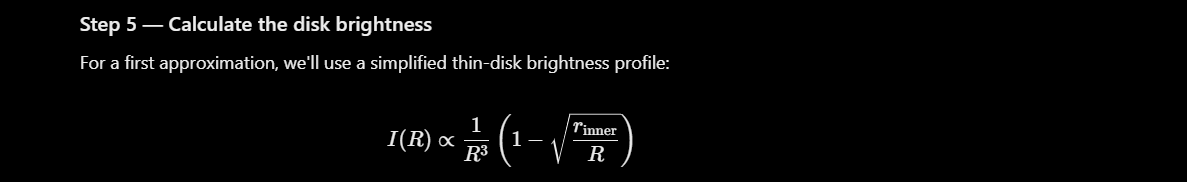

In [4]:
# Start with zero brightness everywhere
brightness = np.zeros_like(R)

# Only calculate brightness inside the disk boundaries
disk_mask = (R >= r_inner) & (R <= r_outer)

# Calculate the brightness profile
brightness[disk_mask] = (
    (r_inner / R[disk_mask])**3
    * (1 - np.sqrt(r_inner / R[disk_mask]))
)

# Normalize brightness to the range 0 to 1
brightness = brightness / brightness.max()

print("Minimum brightness:", brightness.min())
print("Maximum brightness:", brightness.max())

Minimum brightness: 0.0
Maximum brightness: 1.0


Render the accretion disk

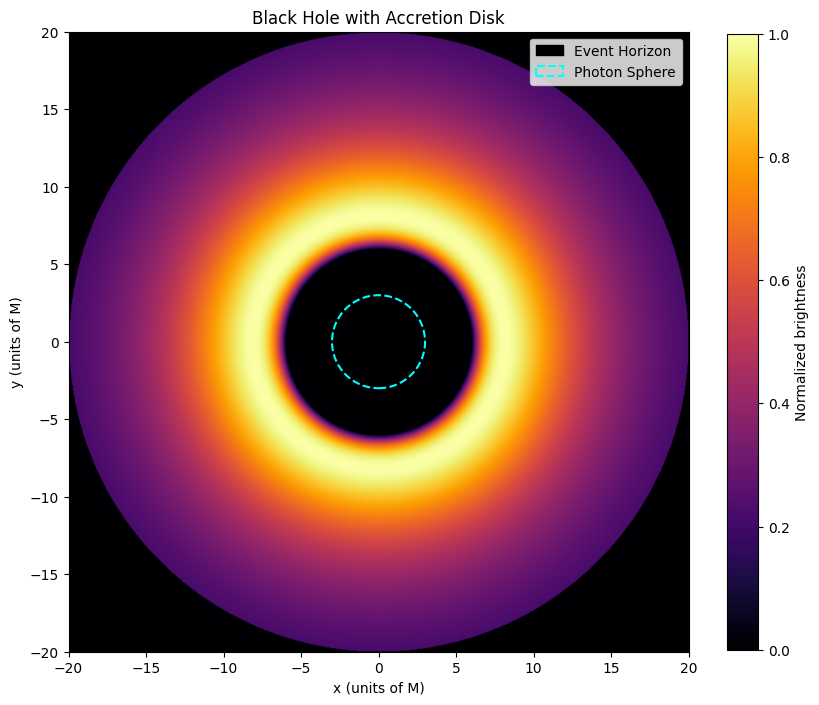

In [5]:
fig, ax = plt.subplots(figsize=(10, 10))

# Display the brightness field
image = ax.imshow(
    brightness,
    extent=[-r_outer, r_outer, -r_outer, r_outer],
    origin="lower",
    cmap="inferno",
    interpolation="bilinear"
)

# Draw the event horizon
ax.add_patch(
    Circle(
        (0, 0),
        r_s,
        color="black",
        label="Event Horizon"
    )
)

# Draw the photon sphere
ax.add_patch(
    Circle(
        (0, 0),
        r_ph,
        fill=False,
        linestyle="--",
        linewidth=1.5,
        edgecolor="cyan",
        label="Photon Sphere"
    )
)

# Configure the plot
ax.set_aspect("equal")
ax.set_xlim(-r_outer, r_outer)
ax.set_ylim(-r_outer, r_outer)
ax.set_xlabel("x (units of M)")
ax.set_ylabel("y (units of M)")
ax.set_title("Black Hole with Accretion Disk")
ax.legend()

# Add a brightness scale
colorbar = plt.colorbar(image, ax=ax, shrink=0.8)
colorbar.set_label("Normalized brightness")

plt.show()

Make the disk more visually interesting

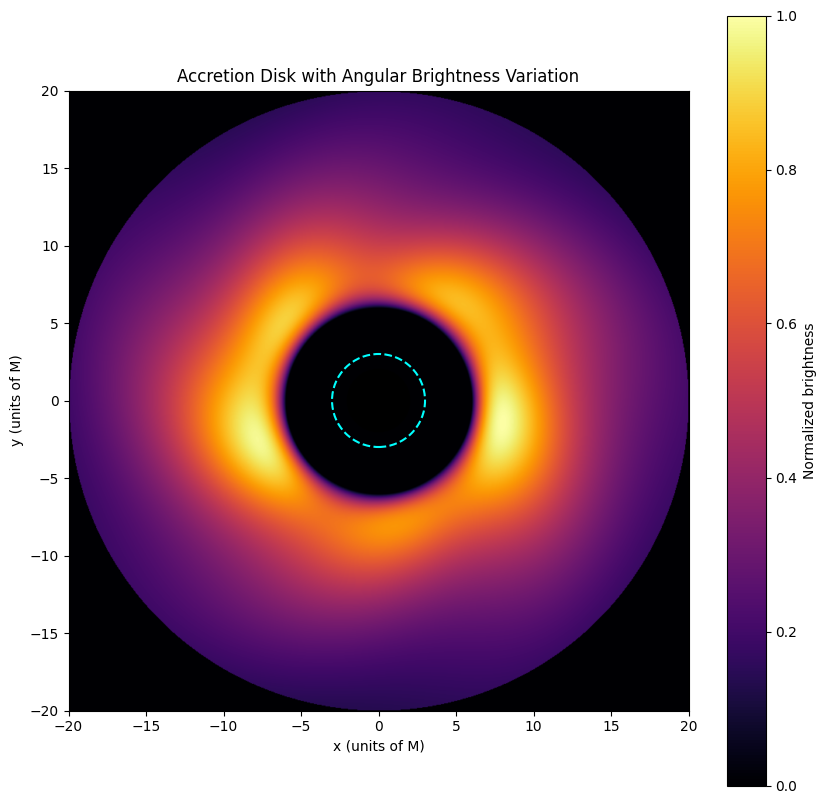

In [6]:
# Calculate the angle of each point around the black hole
phi = np.arctan2(Y, X)

# Create a subtle angular brightness variation
angular_pattern = (
    1
    + 0.15 * np.cos(2 * phi)
    + 0.08 * np.sin(5 * phi + R / 3)
)

# Apply the pattern and normalize again
textured_brightness = brightness * angular_pattern
textured_brightness = (
    textured_brightness / textured_brightness.max()
)

fig, ax = plt.subplots(figsize=(10, 10))

image = ax.imshow(
    textured_brightness,
    extent=[-r_outer, r_outer, -r_outer, r_outer],
    origin="lower",
    cmap="inferno",
    interpolation="bilinear"
)

ax.add_patch(Circle((0, 0), r_s, color="black"))
ax.add_patch(
    Circle(
        (0, 0),
        r_ph,
        fill=False,
        linestyle="--",
        edgecolor="cyan",
        linewidth=1.5
    )
)

ax.set_aspect("equal")
ax.set_xlabel("x (units of M)")
ax.set_ylabel("y (units of M)")
ax.set_title("Accretion Disk with Angular Brightness Variation")

plt.colorbar(image, ax=ax, label="Normalized brightness")
plt.show()